# 2.13 · Model errors: $\mathbf C_d$ and $\mathbf C_p$

Every inversion compares data with predictions. The data are wrong by a little (instrument noise), and so are the
predictions, because the forward model is never the true Earth (a simplified elastic structure, an approximate
fault geometry). Notebooks 2.07-2.09 treated only the first kind of error. This notebook adds the second and shows
what happens to the posterior when it is left out.

**Words this notebook defines:** measurement error, prediction (model) error, $\mathbf C_d$, $\mathbf C_p$, misfit
covariance $\mathbf C_\chi$, sensitivity to a structural parameter, coverage, absorbed vs visible model error,
per-data-set noise scale $\sigma_k$.

**Before this:** [2.01](2-01_basics.ipynb) (section 7), [2.07](2-07_least_squares.ipynb), [2.08](2-08_bayesian_linear_map.ipynb). · **You will be able to:** tell measurement error from prediction
error; build $\mathbf C_p$ from the sensitivity of the forward model to an uncertain structural parameter; state the
assumptions behind $\mathbf C_\chi = \mathbf C_d + \mathbf C_p$; show by coverage what ignoring model error costs and
why one noise scale per data set cannot replace $\mathbf C_p$. · **Optional sections:** none.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| antiplane fault slip (as in notebook 2.33) | 30 patches (0-30 km depth) | 24 stations | screw-dislocation Green's functions $\mathbf d = \mathbf G(\theta)\,\mathbf m$ | linear in slip, nonlinear in the structural parameter θ |
| worked example (section 2) | 2 patches | 3 stations | same | linear in slip |

Prior on slip in every section: Gaussian, mean 1 m, standard deviation 1 m, Matérn correlation (ν = 1.5, ℓ = 5 km)
between patches. Measurement noise σ = 3 mm, independent ($\mathbf C_d = \sigma^2\mathbf I$).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from scipy.special import kv, gamma
from scipy.optimize import minimize_scalar

C_D, C_K, C_P = S.ORANGE, S.AQUA, S.BLUE            # C_d only, noise scale sigma_k, C_d + C_p (one colour each)
LAB = {"Cd": "$\\mathbf{C}_d$ only", "fk": "$\\mathbf{C}_d$ scaled by $\\sigma_k^2$", "Cp": "$\\mathbf{C}_d + \\mathbf{C}_p$"}
NAME = {"Cd": "C_d only", "fk": "C_d scaled by sigma_k^2", "Cp": "C_d + C_p"}       # plain names for printed tables
COL = {"Cd": C_D, "fk": C_K, "Cp": C_P}

N = 30
z_edges = np.linspace(0.0, 30.0, N + 1)                      # patch edges (km)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])                      # patch centres (km)
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])                                 # 24 stations on both sides of the fault (km)
sig = 3.0                                                    # measurement noise (mm)
Cd = sig ** 2 * np.eye(xs.size)


def patch_disp(x, z1, z2):
    """Surface displacement per unit slip of a patch between depths z1 and z2 (antiplane screw dislocation)."""
    return (np.arctan(z2 / x) - np.arctan(z1 / x)) / np.pi


def Gmat(scale=1.0, x=xs, edges=z_edges):
    """Green's functions (mm per m of slip). scale stretches all depths: the structural parameter theta = scale - 1."""
    ze = edges * scale
    return 1000.0 * np.array([[patch_disp(xx, ze[j], ze[j + 1]) for j in range(len(ze) - 1)] for xx in x])


def matern(dist, ell, nu):
    dist = np.maximum(dist, 1e-12)
    a = np.sqrt(2 * nu) * dist / ell
    c = (2 ** (1 - nu) / gamma(nu)) * a ** nu * kv(nu, a)
    c[dist < 1e-10] = 1.0
    return c


Cm = matern(np.abs(zc[:, None] - zc[None, :]), 5.0, 1.5) + 1e-9 * np.eye(N)   # prior covariance (sd 1 m)
m0 = np.full(N, 1.0)                                                           # prior mean (m)
Lm = np.linalg.cholesky(Cm)
G0 = Gmat()                                                                    # the Green's functions we invert with


def post(G, d, Cchi):
    """Exact linear-Gaussian posterior with misfit covariance Cchi (Kalman-gain form)."""
    Sm = G @ Cm @ G.T + Cchi
    K = np.linalg.solve(Sm, G @ Cm).T
    mean = m0 + K @ (d - G @ m0)
    C = Cm - K @ G @ Cm
    return mean, 0.5 * (C + C.T)


def sensitivity(m_ref, h=1e-4):
    """k_theta = d(G(theta) m_ref)/d theta at theta = 0, by central differences (mm per unit theta)."""
    return (Gmat(1 + h) @ m_ref - Gmat(1 - h) @ m_ref) / (2 * h)


def noise_scale(d, G=G0):
    """Per-data-set noise scale sigma_k fitted to the residuals: maximises p(d | sigma_k) (empirical Bayes)."""
    r = d - G @ m0
    Sg = G @ Cm @ G.T

    def nll(lf):
        Sm = Sg + np.exp(2 * lf) * Cd
        return 0.5 * (r @ np.linalg.solve(Sm, r) + np.linalg.slogdet(Sm)[1])
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 5), method="bounded").x))

## 1. Two kinds of error

**In plain words.** $\mathbf C_d$ says how wrong the *instrument* is: how far a GPS reading may scatter around the
true displacement. $\mathbf C_p$ says how wrong our *physics* is: how far the prediction of a perfect slip model may be
from the truth because the forward model uses an approximate Earth. Both make data and predictions disagree, so
both belong in the comparison. They differ in shape: instrument errors are usually independent from station to
station, while a wrong Earth model moves the predictions of neighbouring stations together.

**Precisely.** The data come from the true structure $\theta_\text{true}$, the inversion uses an estimate $\hat\theta$:

$$\mathbf d = \mathbf G(\theta_\text{true})\,\mathbf m + \mathbf e,\qquad \mathbf e\sim N(\mathbf 0,\mathbf C_d).$$

To first order, $\mathbf G(\theta_\text{true})\mathbf m \approx \mathbf G(\hat\theta)\mathbf m + \mathbf k_\theta\,\delta\theta$ with the
sensitivity $\mathbf k_\theta = \partial\big(\mathbf G(\theta)\mathbf m\big)/\partial\theta$ at $\hat\theta$ (a one-column
Jacobian, 2.10: how much each prediction changes per unit change of the structural parameter). If the structural error
$\delta\theta$ is uncertain with standard deviation $\sigma_\theta$, the residual $\mathbf d - \mathbf G(\hat\theta)\mathbf m$ is Gaussian with

$$\mathbf C_\chi = \mathbf C_d + \mathbf C_p,\qquad \mathbf C_p = \sigma_\theta^2\,\mathbf k_\theta\mathbf k_\theta^\top$$

(Duputel et al. 2014; with several uncertain parameters $\mathbf C_p = \mathbf K_\theta\mathbf C_\theta\mathbf K_\theta^\top$, one column
of $\mathbf K_\theta$ per parameter; lowercase $\mathbf k$ here to keep $\mathbf K$ for the Kalman gain). The likelihood then
uses $\mathbf C_\chi$ wherever 2.07-2.09 used $\mathbf C_d$. Because $\mathbf k_\theta$ depends on the slip, it is evaluated at a reference
slip model; this notebook uses the slip estimated with $\mathbf C_d$ alone.

**What adding the two covariances assumes.** $\mathbf C_\chi = \mathbf C_d + \mathbf C_p$ is the covariance of a sum of two
errors, and it is right only when:
1. **both errors have zero mean.** A structural error that is known to push predictions one way (a model that is
   biased, not just uncertain) must be corrected or modelled; a covariance only describes scatter around zero;
2. **the two errors are independent** of each other (the instrument does not know about the Earth model), so no
   cross term appears;
3. **the prediction error is close to linear and Gaussian** in the uncertain structure over its plausible range
   (the first-order expansion above), so that $\sigma_\theta^2\mathbf k_\theta\mathbf k_\theta^\top$ is its covariance;
4. **the reference slip is close enough** to the answer that $\mathbf k_\theta$ evaluated there is representative. If the
   estimate moves a lot, recompute $\mathbf C_p$ at the new estimate (some studies iterate).

When an assumption fails, the recipe still produces a matrix, but its coverage is no longer guaranteed; the
coverage test of section 3 is how to check.

The structural parameter here is a **depth scale**: the true Earth puts every patch at depths multiplied by
$1 + \theta$. It stands in for an unknown elastic layering, which makes a buried slip patch look shallower or deeper
than a half-space model says. We take $\sigma_\theta = 0.15$ (a 15 % depth uncertainty).

saved figures/2-13_two_errors.png


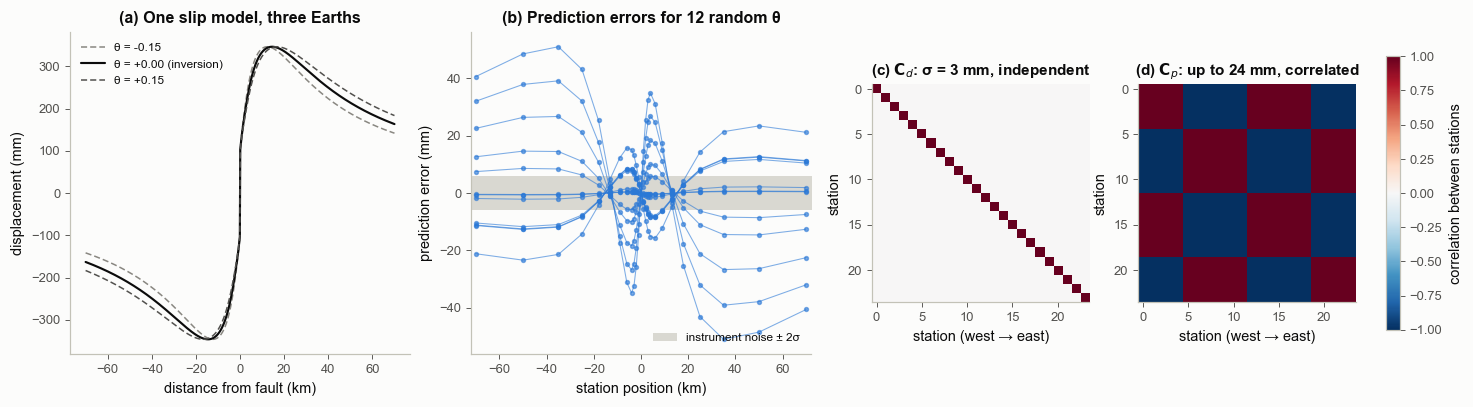

prediction-error standard deviation from sigma_theta = 0.15: largest 23.8 mm, median 14.9 mm (instrument noise 3 mm)
stations where it exceeds the instrument noise: 24 of 24


In [2]:
SIG_TH = 0.15
rng = np.random.default_rng(9)
m_demo = m0 + Lm @ rng.standard_normal(N)                    # one slip model drawn from the prior
k_demo = sensitivity(m_demo)
Cp_demo = SIG_TH ** 2 * np.outer(k_demo, k_demo)
xx = np.linspace(-70, 70, 1401)
xx = xx[np.abs(xx) > 1e-6]

fig, axs = plt.subplots(1, 4, figsize=(16.5, 3.8), gridspec_kw=dict(width_ratios=[1.25, 1.25, 1, 1]))
ax = axs[0]
for th, shade in [(-0.15, S.MUTED), (0.0, S.INK), (0.15, S.INK2)]:
    ax.plot(xx, Gmat(1 + th, x=xx) @ m_demo, color=shade, lw=1.4 if th == 0 else 1.0,
            ls="-" if th == 0 else (0, (4, 2)), label=f"θ = {th:+.2f}" + (" (inversion)" if th == 0 else ""))
ax.set_xlabel("distance from fault (km)"); ax.set_ylabel("displacement (mm)")
ax.set_title("(a) One slip model, three Earths")
ax.legend(fontsize=7.8, loc="upper left")
ax = axs[1]
for i in range(12):
    th = SIG_TH * rng.standard_normal()
    ax.plot(xs, (Gmat(1 + th) - G0) @ m_demo, "o-", color=C_P, ms=2.5, lw=0.7, alpha=0.6)
ax.fill_between([-75, 75], -2 * sig, 2 * sig, color="#d9d8d1", lw=0, label="instrument noise ± 2σ")
ax.set_xlim(-72, 72)
ax.set_xlabel("station position (km)"); ax.set_ylabel("prediction error (mm)")
ax.set_title("(b) Prediction errors for 12 random θ")
ax.legend(fontsize=7.8, loc="lower right")
sd_p = np.sqrt(np.diag(Cp_demo))
for ax, Cmat, t in [(axs[2], Cd, f"(c) $\\mathbf{{C}}_d$: σ = {sig:.0f} mm, independent"),
                    (axs[3], Cp_demo, f"(d) $\\mathbf{{C}}_p$: up to {sd_p.max():.0f} mm, correlated")]:
    sdv = np.sqrt(np.diag(Cmat))
    im = ax.imshow(Cmat / np.outer(sdv, sdv), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("station (west → east)"); ax.set_ylabel("station")
fig.colorbar(im, ax=axs[2:], label="correlation between stations", shrink=0.85)
bk.savefig(fig, "2-13_two_errors")
plt.show()
sd_p = np.sqrt(np.diag(Cp_demo))
print("prediction-error standard deviation from sigma_theta = 0.15: largest %.1f mm, median %.1f mm (instrument noise %.0f mm)"
      % (sd_p.max(), np.median(sd_p), sig))
print("stations where it exceeds the instrument noise: %d of %d" % (np.sum(sd_p > sig), xs.size))

**How to read it.** (a) The same slip seen through three Earths: a deeper Earth (θ > 0) spreads the signal out,
a shallower one sharpens it. (b) The difference between a perturbed Earth and the one we invert with, for twelve
random depth scales: smooth curves that move all stations of one side together, at many stations larger than the
instrument noise (numbers printed above). (c, d) The two matrices drawn as correlations, so their *shape* can be
compared (their sizes are in the titles): $\mathbf C_d$ is a diagonal (each station on its own); $\mathbf C_p$ is a full
pattern of ±1, because one structural error moves every prediction at once, some up and some down.

**Common misreadings.**
* "Model error is just extra noise." Its size may be similar, but its *shape* is not: it is correlated across
  stations and follows the physics. Treating it as independent noise gets both its effect and its weight wrong.
* "If the forward model were wrong, the fit would be bad." Section 3 shows the opposite: here the slip absorbs most
  of the error and the residuals look like pure noise.

## 2. Worked example: three stations, two patches

Two slip patches, 0-10 km and 10-20 km deep, stations 5, 15 and 40 km from the fault, prior slip $N(1, 1^2)$ m on
each patch independently, σ = 3 mm, depth scale uncertain by $\sigma_\theta = 0.15$. The steps:

1. the Green's functions $\mathbf G$ (3 stations × 2 patches, mm per metre of slip);
2. the sensitivity $\mathbf k_\theta = \partial(\mathbf G(\theta)\,\mathbf m_\text{ref})/\partial\theta$, here at the reference slip
   $\mathbf m_\text{ref} = (1, 1)$ m (the prior mean);
3. $\mathbf C_p = \sigma_\theta^2\mathbf k_\theta\mathbf k_\theta^\top$;
4. the posterior covariance $\tilde{\mathbf C}_m = (\mathbf C_m^{-1} + \mathbf G^\top\mathbf C^{-1}\mathbf G)^{-1}$, once with $\mathbf C = \mathbf C_d$ and once
   with $\mathbf C = \mathbf C_d + \mathbf C_p$: standard deviation of each patch and their correlation.

In [3]:
x3 = np.array([5.0, 15.0, 40.0])
e3 = np.array([0.0, 10.0, 20.0])
G3 = Gmat(1.0, x=x3, edges=e3)
h = 1e-5
mref = np.array([1.0, 1.0])
k3 = (Gmat(1 + h, x=x3, edges=e3) - Gmat(1 - h, x=x3, edges=e3)) @ mref / (2 * h)
Cd3 = sig ** 2 * np.eye(3)
Cp3 = SIG_TH ** 2 * np.outer(k3, k3)
print("step 1  G (mm per m of slip; columns = shallow, deep patch):\n", np.round(G3, 1))
print("step 2  k_theta (mm per unit theta):", np.round(k3, 2), "-> one sigma_theta moves the predictions by",
      np.round(SIG_TH * k3, 2), "mm")
print("step 3  C_p (mm^2):\n", np.round(Cp3, 2))
for name, Cc in [("C_d      ", Cd3), ("C_d + C_p", Cd3 + Cp3)]:
    Cpost = np.linalg.inv(np.eye(2) / 1.0 ** 2 + G3.T @ np.linalg.solve(Cc, G3))
    sdp = np.sqrt(np.diag(Cpost))
    print(f"step 4  with {name}: posterior sd shallow {sdp[0]:.3f} m, deep {sdp[1]:.3f} m, "
          f"correlation {Cpost[0, 1] / (sdp[0] * sdp[1]):+.2f}")

step 1  G (mm per m of slip; columns = shallow, deep patch):
 [[352.4  69.6]
 [187.2 108. ]
 [ 78.   69.6]]
step 2  k_theta (mm per unit theta): [ 74.9  152.79 127.32] -> one sigma_theta moves the predictions by [11.23 22.92 19.1 ] mm
step 3  C_p (mm^2):
 [[126.21 257.48 214.56]
 [257.48 525.25 437.71]
 [214.56 437.71 364.76]]
step 4  with C_d      : posterior sd shallow 0.014 m, deep 0.038 m, correlation -0.84
step 4  with C_d + C_p: posterior sd shallow 0.021 m, deep 0.192 m, correlation -0.84


A one-sigma depth error (15 %) moves the predictions at all three stations by several times the instrument noise
(step 2). Its main effect lands on the deep patch, whose uncertainty grows several-fold, while the shallow patch's
grows much less (step 4): a deeper Earth looks like slip moved between the patches, so the data can no longer tell
how much slip is deep. A single uncertain parameter gives a rank-one $\mathbf C_p$ (every column of step 3 is a multiple of
$\mathbf k_\theta$); several independent structural parameters give a higher rank.

## 3. What leaving $\mathbf C_p$ out does to the answer

**In plain words.** If the physics is slightly wrong and you do not say so, the inversion trusts the data as if
the only error were the instrument's. It then explains the data with a slip model that compensates for the wrong
Earth (here: slip at the wrong depth), and reports a small uncertainty around it. The answer is confidently off.

**Precisely.** Three inversions of the same data, all with the same prior:
* $\mathbf C_d$ only;
* $\mathbf C_d$ multiplied by a noise scale $\sigma_k^2$ fitted to the residuals (maximising $p(\mathbf d\mid\sigma_k)$; this is
  the *empirical-Bayes* version, which estimates a setting of the model from the data and then treats it as known
  (2.29), of sampling a per-data-set $\sigma_k$, as hierarchical inversions do, 2.30);
* $\mathbf C_\chi = \mathbf C_d + \mathbf C_p$, with $\mathbf k_\theta$ evaluated at the $\mathbf C_d$-only slip.

First one data set whose true Earth is 20 % deeper than the one we invert with ($\theta_\text{true} = 0.2$).

saved figures/2-13_one_realization.png


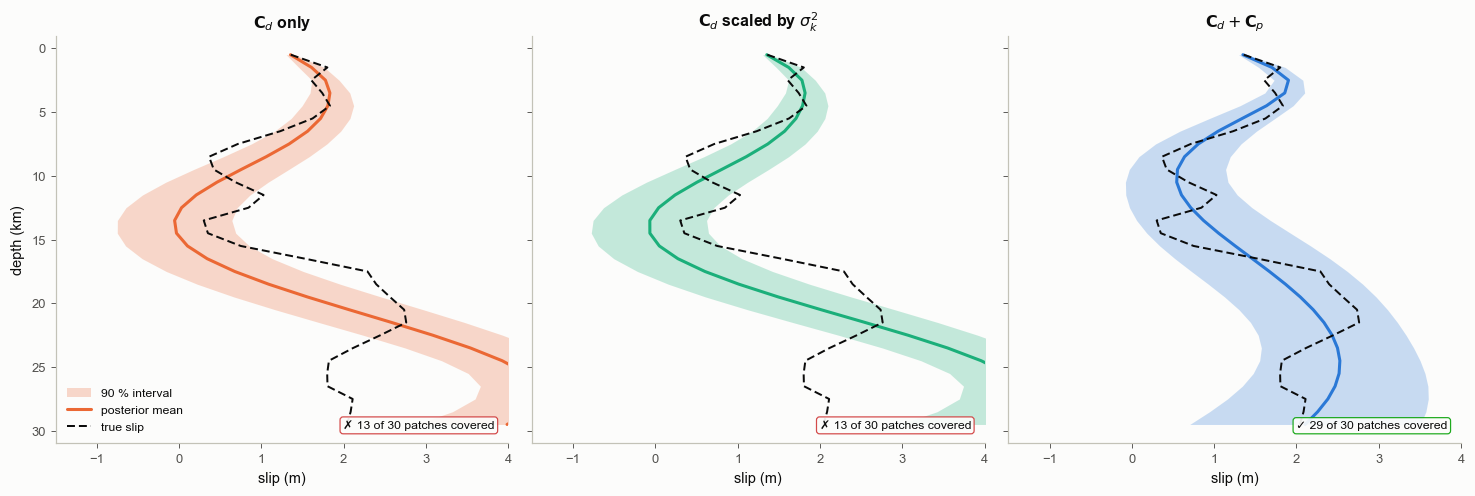

true depth scale theta = 0.2; fitted noise scale sigma_k = 0.91
residuals of the C_d-only fit: chi^2/N = 0.68  (1 means 'at the noise level')
C_d only                : mean posterior sd 0.389 m, patches whose 90 % interval contains the true slip: 13 of 30
C_d scaled by sigma_k^2 : mean posterior sd 0.384 m, patches whose 90 % interval contains the true slip: 13 of 30
C_d + C_p               : mean posterior sd 0.457 m, patches whose 90 % interval contains the true slip: 29 of 30


In [4]:
def three_inversions(d):
    mA, CA = post(G0, d, Cd)
    f = noise_scale(d)
    mF, CF = post(G0, d, f ** 2 * Cd)
    kth = sensitivity(mA)
    mC, CC = post(G0, d, Cd + SIG_TH ** 2 * np.outer(kth, kth))
    return {"Cd": (mA, CA), "fk": (mF, CF), "Cp": (mC, CC)}, f


rng1 = np.random.default_rng(21)
m_true = m0 + Lm @ rng1.standard_normal(N)
th_true = 0.20
d1 = Gmat(1 + th_true) @ m_true + sig * rng1.standard_normal(xs.size)
res1, f1 = three_inversions(d1)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.6), sharey=True)
for ax, key in zip(axs, ["Cd", "fk", "Cp"]):
    mm, CC = res1[key]
    sd = np.sqrt(np.diag(CC))
    ax.fill_betweenx(zc, mm - 1.645 * sd, mm + 1.645 * sd, color=COL[key], alpha=0.25, lw=0, label="90 % interval")
    ax.plot(mm, zc, color=COL[key], lw=2, label="posterior mean")
    ax.plot(m_true, zc, color=S.INK, lw=1.3, ls=(0, (4, 2)), label="true slip")
    inside = np.abs(m_true - mm) <= 1.645 * sd
    S.badge(ax, f"{inside.sum()} of {N} patches covered", ok=inside.mean() >= 0.8, loc="lower right", fs=8)
    ax.set_title(LAB[key], fontsize=10.5)
    ax.set_xlabel("slip (m)")
    ax.set_xlim(-1.5, 4.0)
axs[0].set_ylabel("depth (km)"); axs[0].invert_yaxis()
axs[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-13_one_realization")
plt.show()
r_cd = d1 - G0 @ res1["Cd"][0]
print(f"true depth scale theta = {th_true}; fitted noise scale sigma_k = {f1:.2f}")
print(f"residuals of the C_d-only fit: chi^2/N = {np.sum(r_cd ** 2) / sig ** 2 / xs.size:.2f}  (1 means 'at the noise level')")
for key in res1:
    sd = np.sqrt(np.diag(res1[key][1]))
    print(f"{NAME[key]:24s}: mean posterior sd {sd.mean():.3f} m, "
          f"patches whose 90 % interval contains the true slip: {np.sum(np.abs(m_true - res1[key][0]) <= 1.645 * sd)} of {N}")

**How to read it.** The dashed line is the true slip, the band the 90 % interval. With $\mathbf C_d$ only, the
inversion fits the data at the noise level (χ²/N printed above), yet places slip at the wrong depths with a narrow
band that misses the truth on many patches. The fitted noise scale stays close to one, because the residuals
give no hint that anything is wrong: **the slip has absorbed the model error**. Only $\mathbf C_p$, which comes from
the physics of the uncertain parameter rather than from the residuals, widens the band where the model error
acts. One data set proves little, so the next cell repeats the experiment 400 times.

In [5]:
def coverage_experiment(sig_th_true, n_rep=400, seed=1):
    """Draw slip from the prior and theta ~ N(0, sig_th_true^2), invert three ways, record 90 % coverage per patch."""
    rng_ = np.random.default_rng(seed)
    cov = {k: np.zeros((n_rep, N), bool) for k in ["Cd", "fk", "Cp"]}
    fs = np.zeros(n_rep)
    for r in range(n_rep):
        mt = m0 + Lm @ rng_.standard_normal(N)
        th = sig_th_true * rng_.standard_normal()
        d = Gmat(1 + th) @ mt + sig * rng_.standard_normal(xs.size)
        res, fs[r] = three_inversions(d)
        for key, (mm, CC) in res.items():
            cov[key][r] = np.abs(mt - mm) <= 1.645 * np.sqrt(np.diag(CC))
    return cov, fs


cov15, f15 = coverage_experiment(SIG_TH)
bands = [(0, 10, "0-10 km"), (10, 20, "10-20 km"), (20, 30, "20-30 km")]
print("share of 90 % intervals that contain the true slip (400 repeats, theta ~ N(0, 0.15^2)):")
print(f"{'':28s} {'all':>6s} " + " ".join(f"{b[2]:>9s}" for b in bands))
for key in cov15:
    row = [cov15[key].mean()] + [cov15[key][:, (zc > lo) & (zc < hi)].mean() for lo, hi, _ in bands]
    print(f"{NAME[key]:28s} {row[0]:6.3f} " + " ".join(f"{v:9.3f}" for v in row[1:]))
print("fitted noise scale sigma_k: median %.2f, 5-95 %% range %.2f-%.2f" % (np.median(f15), *np.percentile(f15, [5, 95])))
sweep = [0.05, 0.10, 0.15, 0.20, 0.30]
sweep_cov = {s_: coverage_experiment(s_, n_rep=250, seed=7)[0] for s_ in sweep}

share of 90 % intervals that contain the true slip (400 repeats, theta ~ N(0, 0.15^2)):
                                all   0-10 km  10-20 km  20-30 km
C_d only                      0.801     0.828     0.827     0.749
C_d scaled by sigma_k^2       0.798     0.823     0.825     0.747
C_d + C_p                     0.882     0.888     0.875     0.882
fitted noise scale sigma_k: median 0.99, 5-95 % range 0.72-1.28


saved figures/2-13_coverage.png


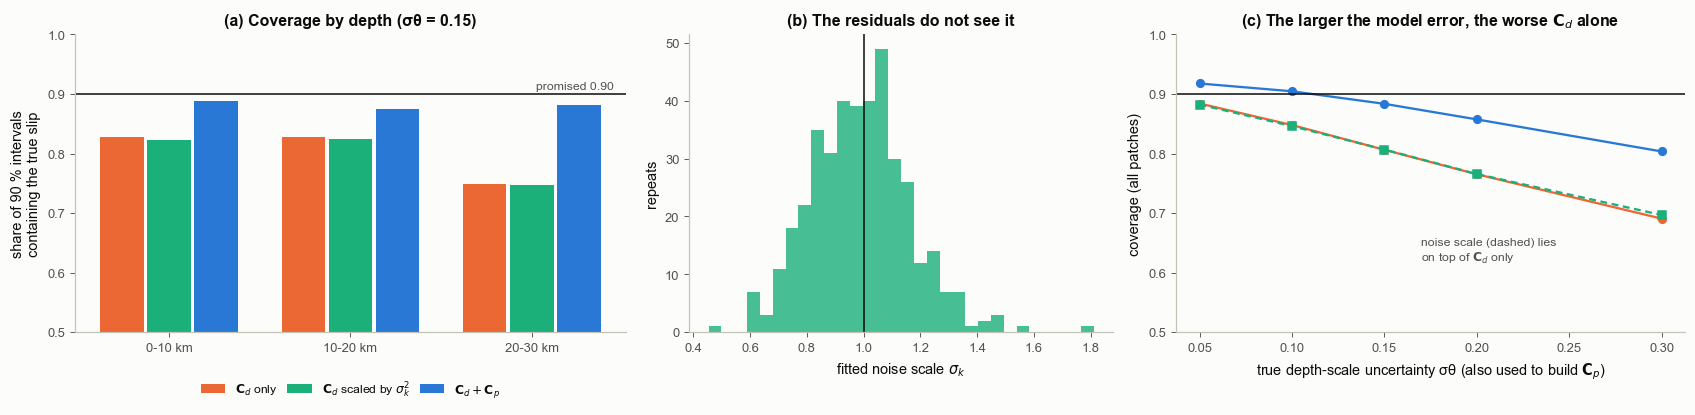

coverage vs sigma_theta (250 repeats each):
  sigma_theta 0.05: C_d only 0.884  C_d scaled by sigma_k^2 0.882  C_d + C_p 0.918
  sigma_theta 0.10: C_d only 0.848  C_d scaled by sigma_k^2 0.846  C_d + C_p 0.905
  sigma_theta 0.15: C_d only 0.806  C_d scaled by sigma_k^2 0.807  C_d + C_p 0.883
  sigma_theta 0.20: C_d only 0.765  C_d scaled by sigma_k^2 0.766  C_d + C_p 0.857
  sigma_theta 0.30: C_d only 0.691  C_d scaled by sigma_k^2 0.697  C_d + C_p 0.803


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1.2]))
ax = axs[0]
w = 0.26
for i, key in enumerate(["Cd", "fk", "Cp"]):
    vals = [cov15[key][:, (zc > lo) & (zc < hi)].mean() for lo, hi, _ in bands]
    ax.bar(np.arange(3) + (i - 1) * w, vals, width=w * 0.92, color=COL[key], label=LAB[key])
ax.axhline(0.9, color=S.INK, lw=1)
ax.text(2.45, 0.905, "promised 0.90", fontsize=8, color=S.INK2, ha="right", va="bottom")
ax.set_xticks(range(3)); ax.set_xticklabels([b[2] for b in bands])
ax.set_ylim(0.5, 1.0); ax.set_ylabel("share of 90 % intervals\ncontaining the true slip")
ax.set_title("(a) Coverage by depth (σθ = 0.15)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, columnspacing=0.8)
ax = axs[1]
ax.hist(f15, bins=30, color=C_K, alpha=0.8)
ax.axvline(1.0, color=S.INK, lw=1)
ax.set_xlabel("fitted noise scale $\\sigma_k$"); ax.set_ylabel("repeats")
ax.set_title("(b) The residuals do not see it")
ax = axs[2]
for key, mk, ls in [("Cd", "o", "-"), ("fk", "s", (0, (3, 2))), ("Cp", "o", "-")]:
    ax.plot(sweep, [sweep_cov[s_][key].mean() for s_ in sweep], marker=mk, ls=ls, color=COL[key], label=LAB[key], ms=5)
ax.text(0.17, 0.62, "noise scale (dashed) lies\non top of $\\mathbf{C}_d$ only", fontsize=8, color=S.INK2, ha="left")
ax.axhline(0.9, color=S.INK, lw=1)
ax.set_xlabel("true depth-scale uncertainty σθ (also used to build $\\mathbf{C}_p$)")
ax.set_ylabel("coverage (all patches)")
ax.set_title("(c) The larger the model error, the worse $\\mathbf{C}_d$ alone")
ax.set_ylim(0.5, 1.0)
fig.tight_layout()
bk.savefig(fig, "2-13_coverage")
plt.show()
print("coverage vs sigma_theta (250 repeats each):")
for s_ in sweep:
    print(f"  sigma_theta {s_:.2f}: " + "  ".join(f"{NAME[k]} {sweep_cov[s_][k].mean():.3f}" for k in ["Cd", "fk", "Cp"]))

**How to read it.** (a) A 90 % interval should contain the truth nine times in ten (the line). With $\mathbf C_d$ alone it
does so less often, worst at depth, where the depth scale moves the predictions most for a given slip. The noise
scale changes nothing, because (b) the fitted $\sigma_k$ stays near one: the slip absorbed the error, the residuals
look like noise, and a scale fitted to the residuals has nothing to react to. $\mathbf C_d + \mathbf C_p$ brings the coverage
close to the promised value at every depth. (c) The gap grows with the size of the structural uncertainty; at the
largest values $\mathbf C_p$ also falls short, because its first-order (linear) approximation and its reference slip
become less accurate (numbers printed above).

**Common misreadings.**
* "χ²/N ≈ 1, so the uncertainties are right." A good fit only says that *some* model explains the data. When the
  model error can be absorbed by the parameters, it biases them without leaving a trace in the residuals.
* "A larger noise scale is a safe substitute for $\mathbf C_p$." It reacts only to what shows up in the residuals, as the
  next section shows from the other side.

## 4. The opposite case: a model error the slip cannot mimic

**In plain words.** Now the forward model is right, but every station shares an unmodelled common-mode offset
(an error of a few millimetres in the reference frame, the coordinate system the positions are expressed in, the
same for all sites). No slip pattern can produce a uniform
offset at stations on both sides of a strike-slip fault, so the slip is not biased at all. The residuals, however,
are large.

**Precisely.** The data are $\mathbf G\mathbf m + c\,\mathbf 1 + \mathbf e$ with $c\sim N(0, 6^2)$ mm, so the prediction error has
covariance $\mathbf C_p = 6^2\,\mathbf 1\mathbf 1^\top$ ($\mathbf 1$: a vector of ones). On this symmetric network every
column of $\mathbf G$ is orthogonal to $\mathbf 1$ (its entries sum to zero over the stations; checked below), so the
offset carries no information about slip either way.

orthogonality: largest |g_j . 1| over all patch columns = 4.2e-14 mm


C_d only                : coverage 0.905, mean posterior sd 0.389 m
C_d scaled by sigma_k^2 : coverage 0.919, mean posterior sd 0.423 m
C_d + C_p               : coverage 0.905, mean posterior sd 0.389 m
fitted noise scale: median 1.78, 95th percentile 4.47; slip sd inflated by up to a factor 1.30


saved figures/2-13_common_mode.png


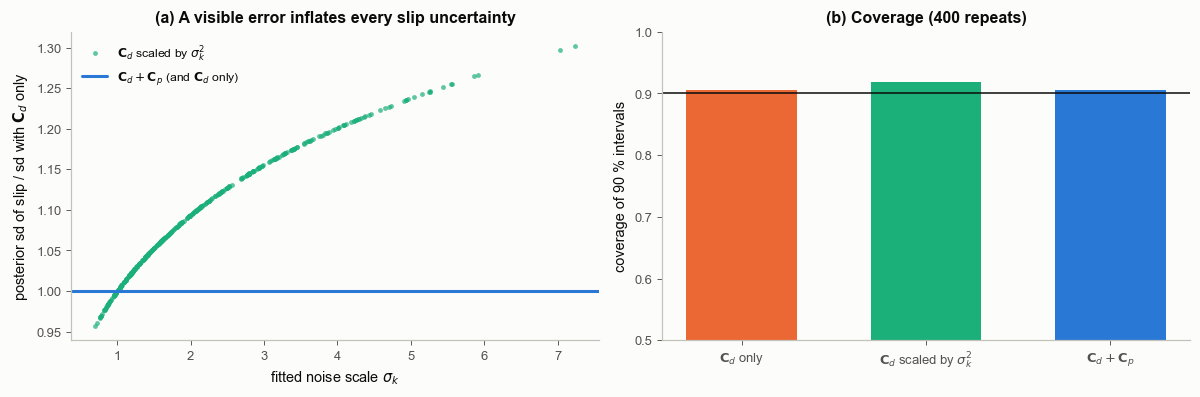

In [7]:
SC = 6.0
one = np.ones(xs.size)
Cp_cm = SC ** 2 * np.outer(one, one)
print("orthogonality: largest |g_j . 1| over all patch columns = %.1e mm" % np.abs(G0.T @ one).max())
rng4 = np.random.default_rng(5)
cov_cm = {k: [] for k in ["Cd", "fk", "Cp"]}
sd_cm = {k: [] for k in cov_cm}
f_cm = []
for r in range(400):
    mt = m0 + Lm @ rng4.standard_normal(N)
    d = G0 @ mt + SC * rng4.standard_normal() + sig * rng4.standard_normal(xs.size)
    f = noise_scale(d)
    f_cm.append(f)
    for key, (mm, CC) in {"Cd": post(G0, d, Cd), "fk": post(G0, d, f ** 2 * Cd), "Cp": post(G0, d, Cd + Cp_cm)}.items():
        sd = np.sqrt(np.diag(CC))
        cov_cm[key].append(np.mean(np.abs(mt - mm) <= 1.645 * sd))
        sd_cm[key].append(sd.mean())
f_cm, ratio = np.array(f_cm), np.array(sd_cm["fk"]) / np.array(sd_cm["Cd"])
for key in cov_cm:
    print(f"{NAME[key]:24s}: coverage {np.mean(cov_cm[key]):.3f}, mean posterior sd {np.mean(sd_cm[key]):.3f} m")
print("fitted noise scale: median %.2f, 95th percentile %.2f; slip sd inflated by up to a factor %.2f"
      % (np.median(f_cm), np.percentile(f_cm, 95), ratio.max()))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
ax = axs[0]
ax.scatter(f_cm, ratio, s=10, color=C_K, alpha=0.7, lw=0, label=LAB["fk"])
ax.axhline(1.0, color=C_P, lw=2, label=LAB["Cp"] + " (and $\\mathbf{C}_d$ only)")
ax.set_xlabel("fitted noise scale $\\sigma_k$"); ax.set_ylabel("posterior sd of slip / sd with $\\mathbf{C}_d$ only")
ax.set_title("(a) A visible error inflates every slip uncertainty")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
keys = ["Cd", "fk", "Cp"]
ax.bar(range(3), [np.mean(cov_cm[k]) for k in keys], color=[COL[k] for k in keys], width=0.6)
ax.axhline(0.9, color=S.INK, lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels([LAB[k] for k in keys], fontsize=8.5)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("coverage of 90 % intervals")
ax.set_title("(b) Coverage (400 repeats)")
fig.tight_layout()
bk.savefig(fig, "2-13_common_mode")
plt.show()

**How to read it.** The offset leaves the slip estimate untouched, so $\mathbf C_d$ alone is already right and so is
$\mathbf C_d + \mathbf C_p$ (they coincide in coverage and width). The noise scale reacts to the large residuals and inflates
every slip uncertainty, by a factor that follows the size of the offset in that realisation (panel a): it widens
the answer where nothing is wrong. Together with section 3 this is the general rule: **a noise scale fitted to the
residuals responds to how large the misfit is, not to how the model error affects the parameters.** $\mathbf C_p$
encodes the second, because it is built from the physics.

**Common misreadings.**
* "Large residuals mean the slip is uncertain." Only if the error could have been produced by slip. Errors in
  directions the parameters cannot reach (here a common mode) say nothing about the parameters.

## 5. Summary

| | instrument error $\mathbf C_d$ | model error $\mathbf C_p$ | noise scale $\sigma_k$ (one factor per data set) |
|---|---|---|---|
| what it describes | scatter of the measurement | how the prediction of a correct slip model differs because the Earth model is approximate | an overall misfit level |
| where it comes from | instrument and processing | the sensitivity of the forward model to uncertain structure, $\mathbf k_\theta$, and that structure's uncertainty | the residuals |
| shape | usually diagonal | full, correlated between stations | the shape of $\mathbf C_d$, scaled |
| absorbed model error (section 3) | blind | widens the posterior where needed | blind (stays near 1) |
| visible but harmless error (section 4) | right | right | inflates everything |

**In practice.** A common shortcut is to estimate one noise scale $\sigma_k$ per data set (2.30). That is the right
tool for balancing data sets whose noise levels are poorly known, but it cannot represent correlated prediction
errors from an approximate elastic structure or fault geometry. Those need $\mathbf C_p$: Duputel et al. (2014) for
elastic structure, Ragon et al. (2018) for fault geometry. Building $\mathbf C_p$ needs one extra set of forward runs
per uncertain structural parameter (the sensitivity), a small cost next to an inversion. A simpler variant adds a
fixed fraction of each observed amplitude to that datum's variance, $(f\,|d_{\rm obs}|)^2$ (Minson et al. 2014): it
sets a size per datum, but no correlation between data.

Next: [**2.14 · Building C_d: noise models**](2-14_building_cd_noise.ipynb).